# AI subscription net adds on card data, and card vs e-receipt churn on Google Play (US)

Engine: `card_net_rules.py` (on top of `card_core_rules.py`). Card payments use the same pull, descriptor families and classification as `card_gross_adds.ipynb`: Omega 2022 consistent-shopper panel via `EARNEST.COMMON.TXNS_CORE_V` plus the unbranded-descriptor patch, rules from `../filters/{provider}.py`. E-receipts use the Google Play filters from `direct_v_channel_comparison.ipynb` (cache `../.cache/channel_cmp/raw.parquet`, NIQ `srs_slice.common.items_v`).

**Steps**
1. **Billing cycle.** For each provider x channel x descriptor family (each way a gross add is identified), the days between a member's consecutive payments for the same provider x channel x plan. p95 and p99 are taken over in-subscription gaps: monthly plans, 1 to 75 days (a gap above 75 days is a new subscription under the gross-add rule, so it is not a billing cycle).
2. **Churn rule.** A subscription churns when the member has no further payment for the same provider x channel x plan within a fixed **45-day cutoff** (both card and e-receipts; the p99 analysis below put the cutoff at about 60 days, which delays churn by a further cycle). Churn is dated at the expected next charge (last payment + median cycle). A payment after a longer gap starts a new subscription (a gross add), so adds and churn reconcile: net adds = the change in subscribers.
3. **Comparison.** Card vs e-receipt churn, gross adds and net adds for the provider x channels where the e-receipts miss under 5% of sign-ups and cancellations and the card data sees the same channel: **ChatGPT, Claude and Perplexity on Google Play**. Rates are used (per start-of-month subscriber), because the two panels differ in size.

Out of scope here: Grok (not in the card brand pull), Muse (about 90 card subscribers), Gemini (card descriptors can't separate Google Play from other Google One billing), and Apple (invisible on cards).

In [1]:
import warnings, pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, FuncFormatter
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="This pattern is interpreted")
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 70); pd.set_option("display.max_rows", 200)
import card_core_rules as CR, card_net_rules as N

raw = pd.read_parquet(CR.CACHE / "raw.parquet")
END = raw.dt.max()
cls = CR.classify(raw)
pay = cls[cls.keep & cls.provider.ne("muse")].rename(columns={"memid": "uid"}).copy()  # Muse: ~90 members, too few to read
pay["plan"] = pay.plan.astype(str)
pay["family"] = ""
for p in pay.provider.unique():
    m = pay.provider.eq(p)
    pay.loc[m, "family"] = CR.family(pay.loc[m, "descr"], p).values
rp, rc = N.gp_receipts()
REND = rp.dt.max()
NAMES = {"chatgpt": "ChatGPT", "claude": "Claude", "gemini": "Gemini", "perplexity": "Perplexity"}
CH = {"web": "web", "google_play": "Google Play"}
lab = lambda i: f"{NAMES[i[0]]} {CH[i[1]]}"
GP = ["chatgpt", "claude", "perplexity"]
print(f"card: {len(pay):,} plan payments, {pay.uid.nunique():,} members, data end {END.date()}")
print(f"e-receipts (Google Play): {len(rp):,} paid receipts, {len(rc):,} cancellations, data end {REND.date()}")
pay.groupby(["provider", "channel"]).agg(payments=("dt", "size"), members=("uid", "nunique"), first=("dt", "min"))

card: 3,695,253 plan payments, 438,673 members, data end 2026-10-25
e-receipts (Google Play): 255,924 paid receipts, 38,450 cancellations, data end 2026-10-20


payments  members      first
provider   channel                                  
chatgpt    google_play    275008    44096 2023-08-23
           web           2577955   308030 2023-02-02
claude     google_play     10269     2853 2024-07-19
           web            314754    62932 2023-09-07
gemini     web            489924    92131 2024-02-08
perplexity google_play      2567      572 2023-11-04
           web             24776     4687 2023-06-08

## 1. Billing cycle by provider x channel x descriptor family (card)

- **p50 / p90 / p95 / p99:** percentiles of in-subscription gaps (monthly plans, 1 to 75 days).
- **pct_26_35:** share of those gaps 26 to 35 days apart (one normal monthly cycle).
- **pct_under_20:** gaps under 20 days (double charges, retries, upgrades mid-cycle).
- **pct_gaps_over_cap:** share of all monthly gaps longer than 75 days (stop and restart).

Families with fewer than 200 gaps are hidden.

In [2]:
g = N.cycle_gaps(pay, ["provider", "channel", "plan"])
rg = N.cycle_gaps(rp, ["provider", "channel"])
FMT = {"p50": "{:.0f}", "p90": "{:.0f}", "p95": "{:.0f}", "p99": "{:.0f}", "gaps": "{:,}", "members": "{:,}",
       "pct_26_35": "{:.1%}", "pct_under_20": "{:.1%}", "pct_gaps_over_cap": "{:.1%}"}
fam = N.cycle_table(g, ["provider", "channel", "family"])
fam[fam.gaps >= 200].style.format(FMT)

In [3]:
pc = N.cycle_table(g, ["provider", "channel"])
print("Pooled by provider x channel (the churn rule uses a fixed CUTOFF instead; see section 4)")
pc.style.format(FMT)

Pooled by provider x channel (the churn rule uses a fixed CUTOFF instead; see section 4)


In [4]:
pl = N.cycle_table(g, ["provider", "channel", "plan"])
print("By plan (200+ gaps)")
pl[pl.gaps >= 200].style.format(FMT)

By plan (200+ gaps)


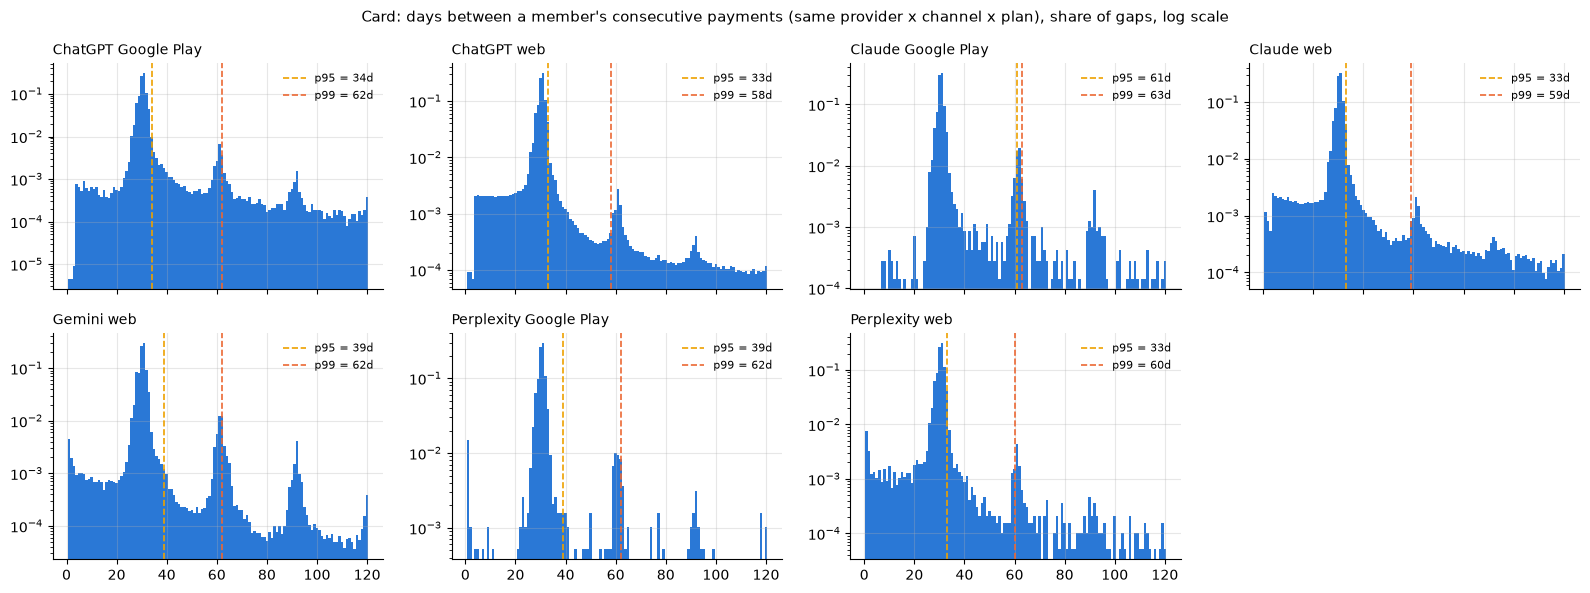

In [5]:
keys = list(pc.index)
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for ax, k in zip(axes.flat, keys):
    s = g[(g.provider == k[0]) & (g.channel == k[1]) & g.cadence.eq("M") & g.gap.between(1, 120)].gap
    h = s.value_counts(normalize=True).sort_index()
    ax.bar(h.index, h.values, width=1, color="#2a78d6")
    for q, c in [("p95", "#eda100"), ("p99", "#eb6834")]:
        ax.axvline(pc.loc[k, q], color=c, ls="--", lw=1.2, label=f"{q} = {pc.loc[k, q]:.0f}d")
    ax.set_yscale("log"); ax.set_title(lab(k), fontsize=10, loc="left"); ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
for ax in axes.flat[len(keys):]: ax.axis("off")
fig.suptitle("Card: days between a member's consecutive payments (same provider x channel x plan), share of gaps, log scale", fontsize=11)
plt.tight_layout(); plt.show()

**Finding: the billing cycle is 31 days, but p99 is about two cycles (58-63 days).**
- About 92-94% of in-subscription gaps are 26-35 days, and the median is 31 days in every provider x channel x family.
- The tail is not a slow drift (36, 40, 45 days). It is a second bump at 56-66 days: one monthly charge missing between two normal ones. This is about 1% of web gaps and 2-6% of Google Play gaps, and the p99 lands on it.
- p95 is 33-34 days on the web and for ChatGPT Google Play. Claude and Perplexity Google Play and Gemini have p95s of 39-61 days, pushed up by a Jul-Aug 2026 skip (section 2).
- **The churn rule therefore uses a fixed 45-day cutoff** (section 4), not p99. 45 days sits past the 26-35 day cycle plus late or retried payments, but before the two-cycle bump. Each gap above 45 days reads as a churn followed by a re-add: about 1.5% of web gaps.

## 2. Is a member's billing cycle consistent?

For members with 3+ consecutive in-subscription gaps:
- **pct_steady:** every gap within 3 days of the member's own median gap.
- **median_member_range_days:** the member's longest gap minus their shortest.
- **late_then_normal:** of gaps above p95, the share followed by a normal gap (<= p95). This is the "t+30, t+40, t+30" pattern.
- **false_churn_p99:** share of in-subscription gaps above p99. The p99 rule reads each as a churn followed by a re-add.

In [6]:
reg = N.regularity(g, ["provider", "channel"], pc.p95, pc.p99)
reg.style.format({"members_3plus_gaps": "{:,}", "pct_steady": "{:.1%}", "median_member_range_days": "{:.0f}",
                  "late_then_normal": "{:.1%}", "false_churn_p99": "{:.2%}"})

### 2a. Member-level steadiness, and p99 for members with a steady history

Hypothesis: p99 is high because it includes members who churned and re-subscribed. Three checks:
1. **Per member** (3+ gaps on one plan): share whose gaps are all 26-35 days, all within 3 days of their own median, the range of their gaps, and the share who ever had a gap above 35 days.
2. **p99 restricted to steady histories:** only gaps preceded by at least r consecutive normal (26-35 day) gaps for the same plan. r = 1 is "paid the prior month".
3. **Anchor test:** of 40-75 day gaps, the share within 2 days of twice the member's own cycle. A re-subscription restarts billing on a random day; a missing charge keeps the billing day.

In [7]:
us = N.user_steadiness(g, ["provider", "channel"])
display(us.style.format({"members": "{:,}", "pct_all_26_35": "{:.1%}", "pct_within_3d": "{:.1%}", "median_range": "{:.0f}",
                         "p90_range": "{:.0f}", "pct_any_over_35": "{:.1%}"}))
stk = N.streak_table(g, ["provider", "channel"])
stk.style.format({c: ("{:,}" if c[1] == "gaps" else "{:.1%}" if c[1] == "pct_over_35" else "{:.0f}") for c in stk.columns})

In [8]:
anc = pd.DataFrame({"card": N.anchor_share(g, ["provider", "channel"]),
                    "e-receipt": N.anchor_share(rg.assign(plan="all"), ["provider", "channel"])})
anc.set_axis([lab(k) for k in anc.index]).style.format("{:.0%}", na_rep="")

,card,e-receipt
ChatGPT Google Play,42%,22%
ChatGPT web,32%,
Claude Google Play,59%,28%
Claude web,26%,
Gemini web,62%,
Perplexity Google Play,68%,16%
Perplexity web,49%,


**Finding: most members are steady, and conditioning on a steady history only helps on the web.**
- **Per member:** 64-78% of members have every gap 26-35 days, and the median member's gaps span 3-5 days. Calendar months alone (28-31 days) account for 3 days. But over their whole history, 15-34% of members have at least one gap above 35 days.
- **"Paid the prior month" barely moves p99:** web 58 → 56-59, Google Play 62-63 → 61-63. With 3+ prior normal months, web p99 is 46-52; with 6+ it is 43-47. Google Play stays at 61-63 even after 6 normal months, and so do the Google Play e-receipts (p99 61-62).
- **Even the steadiest members have 1.6-1.8% of web gaps above 35 days** (2.4% for ChatGPT Google Play). A 35-day rule would read that share of continuing subscribers as churn plus re-add every month.
- **Anchor test:** 26-49% of web gaps of 40-75 days, and 42-68% of Google-billed card gaps, are exactly two cycles (±2 days). The billing day is kept and one charge is missing. A re-subscription would restart billing on a random day. In the Google Play e-receipts only 16-28% of long gaps keep the billing day. So the extra two-cycle gaps on Google-billed cards are mostly charges we don't see, not cancellations.

**Where do the ~60-day gaps come from?** A 56 to 66 day gap means one monthly charge is missing between two normal ones. The chart shows, by the month of the missing charge, the share of continuing payments whose next payment skips a month: card vs Google Play e-receipts. If the skip shows on cards but not in receipts, the charge happened but the card panel didn't record it.

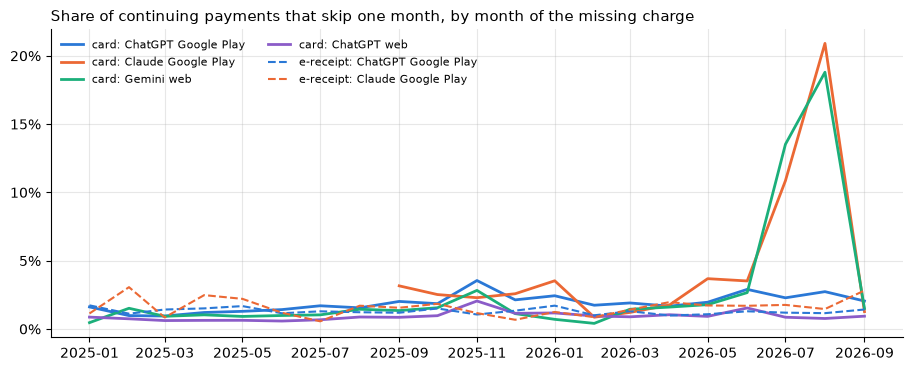

card, share skipping a month:


,ChatGPT Google Play,ChatGPT web,Claude Google Play,Claude web,Gemini web,Perplexity Google Play,Perplexity web
dt,,,,,,,
2026-03,1.9%,0.9%,1.2%,0.7%,1.4%,4.3%,0.9%
2026-04,1.7%,1.0%,1.8%,0.7%,1.6%,2.5%,1.3%
2026-05,2.0%,0.9%,3.7%,0.9%,1.8%,3.8%,0.6%
2026-06,2.9%,1.5%,3.5%,1.3%,2.7%,4.0%,1.6%
2026-07,2.3%,0.9%,10.9%,0.8%,13.5%,12.3%,0.7%
2026-08,2.7%,0.8%,20.9%,0.8%,18.8%,17.0%,1.2%
2026-09,2.0%,0.9%,1.3%,0.9%,1.5%,6.8%,0.1%


In [9]:
def skipped(gg, by):
    m = gg[gg.cadence.eq("M") & gg.gap.between(1, 120)]
    miss = (m.dt + pd.Timedelta(days=31)).dt.to_period("M")
    num = m[m.gap.between(56, 66)].groupby(by).apply(lambda d: miss[d.index].value_counts())
    den = m.groupby(by).apply(lambda d: d.dt.dt.to_period("M").value_counts())
    return (num / den).unstack(by) if isinstance(num, pd.Series) else (num / den).T

sk_card = skipped(g, ["provider", "channel"])
sk_rec = skipped(rg, ["provider", "channel"])
fig, ax = plt.subplots(figsize=(11, 4))
for k, c in [(("chatgpt", "google_play"), "#2a78d6"), (("claude", "google_play"), "#eb6834"), (("gemini", "web"), "#1baf7a"), (("chatgpt", "web"), "#8b5cc8")]:
    s = sk_card[k].loc["2025-01":"2026-09"]
    ax.plot(s.index.to_timestamp(), s.values, color=c, lw=2, label=f"card: {lab(k)}")
for k, c in [(("chatgpt", "google_play"), "#2a78d6"), (("claude", "google_play"), "#eb6834")]:
    s = sk_rec[k].loc["2025-01":"2026-09"]
    ax.plot(s.index.to_timestamp(), s.values, color=c, lw=1.5, ls="--", label=f"e-receipt: {lab(k)}")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Share of continuing payments that skip one month, by month of the missing charge", fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=8, ncol=2); plt.show()
print("card, share skipping a month:"); display(sk_card.loc["2026-03":"2026-09"].pipe(lambda d: d.set_axis([lab(k) for k in d.columns], axis=1)).style.format("{:.1%}"))

**Finding: members keep a steady cycle; the irregularity is skipped months, and on Google-billed cards much of it was our descriptor matching.**
- Of gaps above p95, 58-83% are followed by a normal gap. A late payment is a one-off (one missing charge), not a change of cycle. The "t+30, t+40, t+30" pattern is rare: 36-45 day gaps are about 1-1.5% of all gaps.
- **ChatGPT: fixed.** Some issuers truncate the Google Play descriptor to `GOOGLE *CHATGP MOUNTAIN VIE CA` (no final T). This form grew from Oct 2025 and peaked at about 3.8k panel rows a month in Aug 2026. Before the fix it was not matched, so 10-15% of continuing ChatGPT Google Play subscribers appeared to skip a month in Jul-Aug 2026 (5% in Nov 2025). With `CHATGP` matched, the skip share is a flat 2-3%, close to the e-receipts (about 1.2-1.8%).
- **Not yet checked for the others:** 11-21% of continuing Claude and Perplexity Google Play subscribers, and of Gemini (Google One), still skip a month in Jul-Aug 2026, against 2-4% before. The Google Play e-receipts show no change, so this is likely a similar descriptor change that our patterns miss. These two months are marked as card gap months in sections 5-8.

## 3. Billing cycle on Google Play e-receipts

Google Play sends a priced receipt for each renewal, so the same percentiles can be read from the e-receipts.

In [10]:
rt = N.cycle_table(rg, ["provider", "channel"])
cmp = pd.concat({"card": pc.loc[[(p, "google_play") for p in GP], ["p50", "p95", "p99", "pct_26_35", "gaps"]],
                 "e-receipt": rt[["p50", "p95", "p99", "pct_26_35", "gaps"]]}, axis=1)
cmp.style.format({c: FMT[c[1]] for c in cmp.columns})

**Finding: the cycles now agree for ChatGPT.** Card and e-receipts both have a median of 31 days, p95 of 34 vs 37 days and p99 of 62 days. The ~60-day bump is in both sources (1-2% of receipt gaps), so part of it is real: paused subscriptions, failed payments recovered a month later, or a renewal email that didn't arrive. Claude and Perplexity card p95s are still inflated by the Jul-Aug 2026 skip.

## 4. Card gross adds, churn and net adds by provider x channel

Threshold: a fixed **45-day cutoff** for every provider x channel (`CUTOFF`), annual plans 400 days. Churn is shown only for complete months: a month is complete when every subscription that could churn in it has had 45 days plus 10 days of card posting lag to show a further payment. Later months are censored (hollow markers mark the last complete month).

At **plan level** (the rule as specified), a switch between plans in the same provider x channel is a churn of the old plan plus an add of the new one. The charts use **provider x channel level** (any plan), which matches the e-receipt flows. The table after the charts shows the difference.

last complete churn month: {'ChatGPT Google Play': '2026-09', 'ChatGPT web': '2026-09', 'Claude Google Play': '2026-09', 'Claude web': '2026-09', 'Gemini web': '2026-09', 'Perplexity Google Play': '2026-09', 'Perplexity web': '2026-09'}


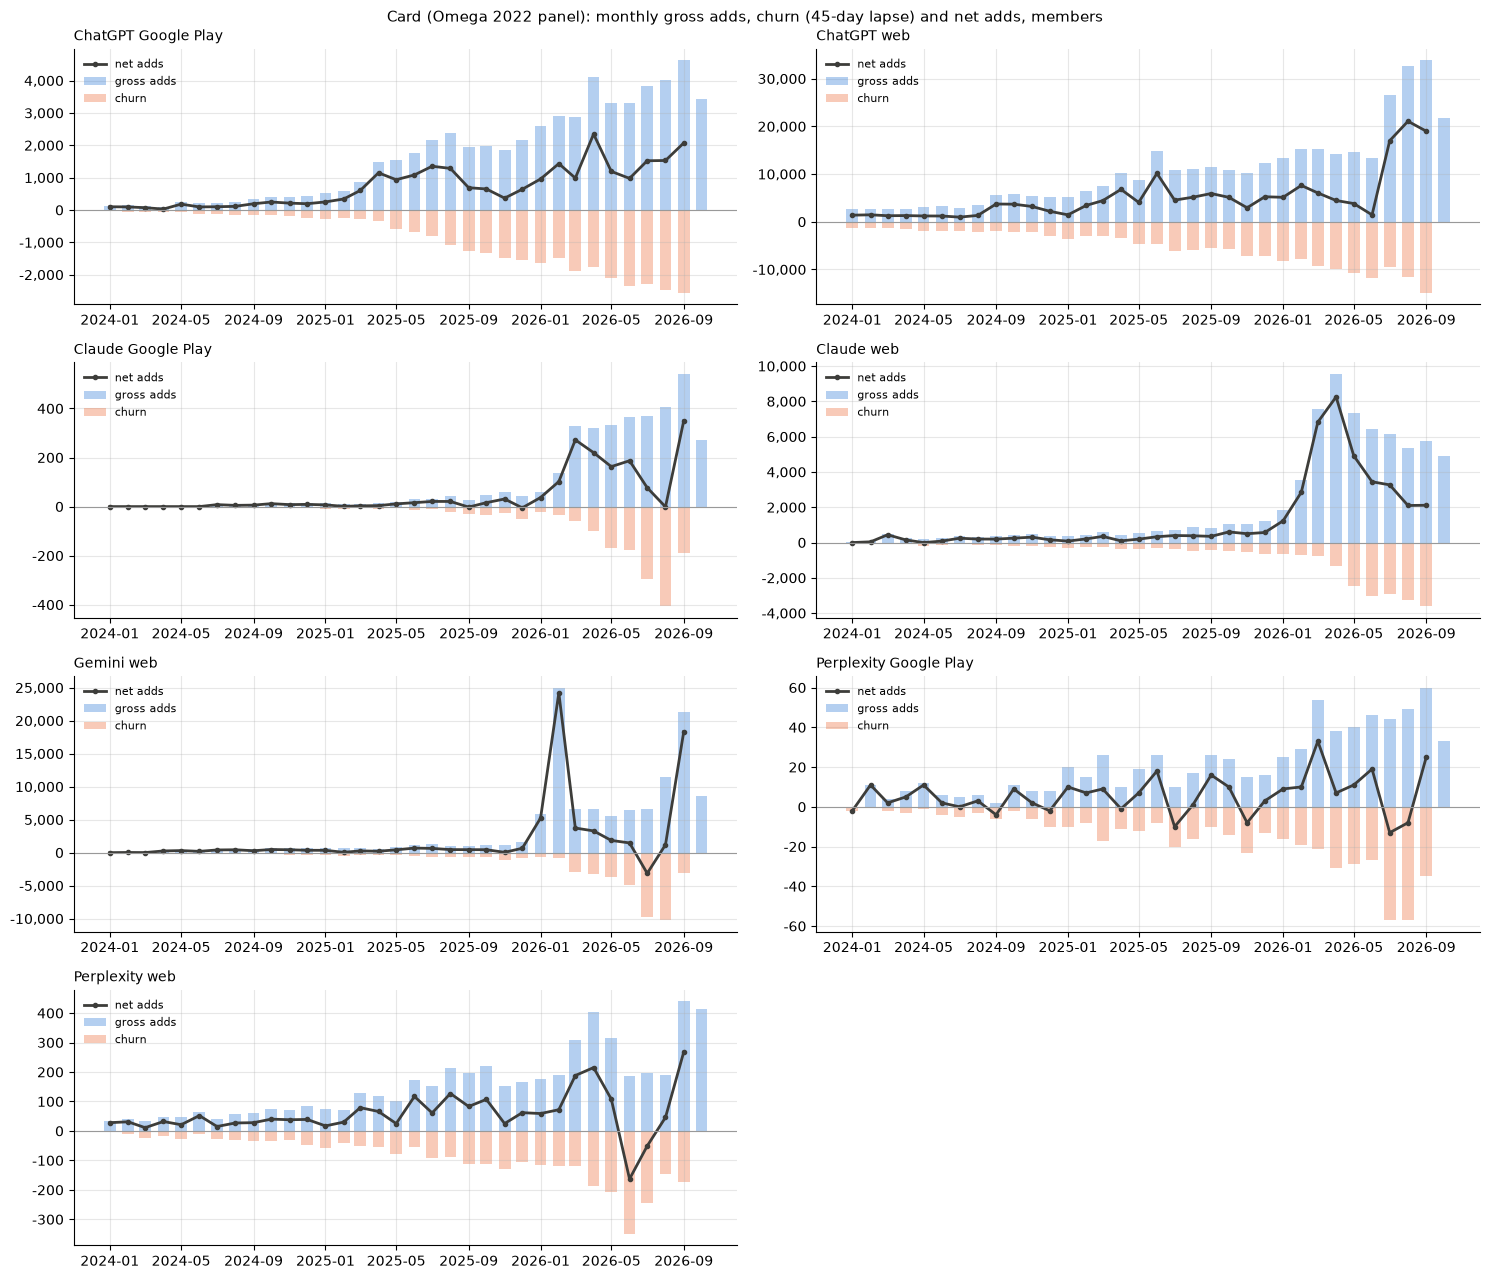

In [11]:
CUTOFF = 45  # days between payments: continuing if the next payment comes within CUTOFF, otherwise churn (p99 was ~60)
THR, CYC = pd.Series(float(CUTOFF), index=pc.index), pc.p50
sp = N.series(pay, ["provider", "channel"], THR, CYC, END, lag=N.CARD_LAG)
sp_plan = N.series(pay, ["provider", "channel", "plan"], THR, CYC, END, lag=N.CARD_LAG)
cm = N.monthly(sp, ["provider", "channel"], start="2024-01", end=END)
cm_plan = N.monthly(sp_plan, ["provider", "channel", "plan"], start="2024-01", end=END)
DONE = {k: N.churn_complete_through(END, THR[k], CYC[k], N.CARD_LAG) for k in THR.index}
cm["complete"] = [m <= DONE[(p, c)] for m, p, c in zip(cm.month, cm.provider, cm.channel)]
for c in ["churn", "churn_rate", "net_adds"]:
    cm.loc[~cm.complete, c] = np.nan
print("last complete churn month:", {lab(k): str(v) for k, v in DONE.items()})

fig, axes = plt.subplots(4, 2, figsize=(15, 13))
for ax, k in zip(axes.flat, keys):
    d = cm[(cm.provider == k[0]) & (cm.channel == k[1])].set_index("month")
    x = d.index.to_timestamp()
    ax.bar(x, d.gross_adds, width=20, color="#2a78d6", alpha=0.35, label="gross adds")
    ax.bar(x, -d.churn, width=20, color="#eb6834", alpha=0.35, label="churn")
    ax.plot(x, d.net_adds, color="#3d3d3a", lw=2, marker="o", ms=3, label="net adds")
    ax.axhline(0, color="#999", lw=0.8); ax.set_title(lab(k), fontsize=10, loc="left")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}")); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
axes.flat[-1].axis("off")
fig.suptitle("Card (Omega 2022 panel): monthly gross adds, churn (45-day lapse) and net adds, members", fontsize=11)
plt.tight_layout(); plt.show()

In [12]:
# plan level vs provider x channel level: plan-level churn includes plan switches within the provider x channel
done = cm[cm.complete & (cm.month >= pd.Period("2025-01"))]
pcl = cm_plan.merge(done[["month", "provider", "channel"]], on=["month", "provider", "channel"])
t = pd.DataFrame({"churn, provider x channel": done.groupby(["provider", "channel"]).churn.sum(),
                  "churn, plan level": pcl.groupby(["provider", "channel"]).churn.sum(),
                  "gross adds, provider x channel": done.groupby(["provider", "channel"]).gross_adds.sum(),
                  "gross adds, plan level": pcl.groupby(["provider", "channel"]).gross_adds.sum()})
t["plan switches (approx.)"] = t["churn, plan level"] - t["churn, provider x channel"]
t["switches % of plan churn"] = t["plan switches (approx.)"] / t["churn, plan level"]
print("2025-01 to each provider x channel's last complete month")
t.set_axis([lab(k) for k in t.index]).style.format({c: "{:,.0f}" for c in t.columns} | {"switches % of plan churn": "{:.1%}"})

2025-01 to each provider x channel's last complete month


,"churn, provider x channel","churn, plan level","gross adds, provider x channel","gross adds, plan level",plan switches (approx.),switches % of plan churn
ChatGPT Google Play,"28,515","29,771","50,881","52,270","1,256",4.2%
ChatGPT web,"153,937","161,698","298,745","308,498","7,761",4.8%
Claude Google Play,"1,682","1,843","3,213","3,390",161,8.7%
Claude web,"23,376","31,788","62,418","72,723","8,412",26.5%
Gemini web,"46,460","49,680","107,354","111,581","3,220",6.5%
Perplexity Google Play,454,468,609,627,14,3.0%
Perplexity web,"2,637","2,798","4,178","4,372",161,5.8%


In [13]:
# monthly churn rate by plan (complete months, plans with 1,000+ subscribers at the start of the month)
cp = cm_plan.merge(cm[["month", "provider", "channel", "complete"]], on=["month", "provider", "channel"])
cp = cp[cp.complete & (cp.subs_start >= 1000) & (cp.month >= pd.Period("2025-01"))]
cp.assign(line=cp.provider.map(NAMES) + " " + cp.channel.map(CH) + " " + cp.plan).pivot_table(
    index="month", columns="line", values="churn_rate").style.format("{:.1%}")

line,ChatGPT Google Play go_M,ChatGPT Google Play plus_M,ChatGPT web go_M,ChatGPT web plus_M,ChatGPT web pro100_M,Claude Google Play pro_M,Claude web max20_M,Claude web max5_M,Claude web pro_A,Claude web pro_M,Gemini web ai_plus_2tb_A,Gemini web ai_plus_2tb_M,Gemini web ai_plus_A,Gemini web ai_plus_M,Gemini web ai_pro_M,Perplexity web pro_M
month,,,,,,,,,,,,,,,,
2025-01,nan%,14.6%,nan%,10.1%,nan%,nan%,nan%,nan%,nan%,13.2%,nan%,nan%,nan%,nan%,12.9%,nan%
2025-02,nan%,12.2%,nan%,7.9%,nan%,nan%,nan%,nan%,nan%,11.0%,nan%,nan%,nan%,nan%,16.3%,nan%
2025-03,nan%,10.9%,nan%,7.3%,nan%,nan%,nan%,nan%,nan%,14.9%,nan%,nan%,nan%,nan%,11.2%,nan%
2025-04,nan%,11.4%,nan%,7.4%,nan%,nan%,nan%,nan%,nan%,14.2%,nan%,nan%,nan%,nan%,9.1%,nan%
2025-05,nan%,14.2%,nan%,9.0%,nan%,nan%,nan%,nan%,nan%,15.3%,nan%,nan%,nan%,nan%,9.4%,nan%
2025-06,nan%,13.2%,nan%,8.3%,nan%,nan%,nan%,nan%,nan%,14.4%,nan%,nan%,nan%,nan%,10.3%,nan%
2025-07,nan%,12.9%,nan%,9.3%,nan%,nan%,nan%,nan%,nan%,14.5%,nan%,nan%,nan%,nan%,11.8%,nan%
2025-08,nan%,14.5%,nan%,8.4%,nan%,nan%,nan%,nan%,nan%,17.3%,nan%,nan%,nan%,nan%,9.6%,nan%
2025-09,nan%,14.3%,nan%,7.2%,nan%,nan%,nan%,nan%,nan%,15.3%,nan%,nan%,nan%,nan%,9.5%,nan%


**Findings (card, 45-day lapse churn, complete months to Sep 2026).**
- Monthly churn per start-of-month subscriber: ChatGPT web Plus about 7-10%, Google Play Plus about 11-15%; Claude web Pro about 12-17%; Gemini AI Pro about 8-12% outside Jul-Aug 2026. Google Play churns faster than web.
- **ChatGPT Google Play is now steady:** 11.5-14.7% a month, with no spikes in Nov 2025 or Jul-Aug 2026.
- Plan switches are 3-6% of plan-level churn for ChatGPT, Gemini and Perplexity, but 27% for Claude web (Pro to Max upgrades). For Claude, a plan-level read overstates churn and gross adds by about 8k each since 2025.
- **Gemini, and Claude and Perplexity on Google Play, still spike in Jul-Aug 2026** (e.g. Gemini AI Pro 21-23% vs about 9%). This is the same kind of missed charge; not fixed yet.

## 5. Card vs e-receipt on Google Play: ChatGPT, Claude, Perplexity

Three churn measures, each per start-of-month subscriber in its own panel:
- **Card (lapse):** no further Google Play payment for the provider within 45 days; dated at the expected next charge. Complete months only.
- **E-receipt (cancellation email):** Google Play cancellation emails (45-day de-duplication), counted only for mailboxes whose subscription was seen in the receipts (the cancellation falls inside a receipt spell: after its first paid receipt and before last receipt + 45 days). Dated at the email.
- **E-receipt (lapse):** the card method applied to Google Play renewal receipts (same 45-day cutoff). This separates a difference between panels from a difference between methods.

E-receipt subscribers = mailboxes in a receipt spell at the start of the month (same spell rule as the cards). Gross adds = spell starts. Comparison from 2025-01 (receipts start 2024-07, so earlier spells are left-censored).

In [14]:
RTHR, RCYC = pd.Series(float(CUTOFF), index=rt.index), rt.p50
csp = sp[sp.provider.isin(GP) & sp.channel.eq("google_play")]
card = cm[cm.provider.isin(GP) & cm.channel.eq("google_play") & (cm.month >= pd.Period("2025-01"))].drop(columns="channel")
rsp = N.series(rp, ["provider", "channel"], RTHR, RCYC, REND, lag=N.RECEIPT_LAG)
rec = N.monthly(rsp, ["provider"], start="2025-01", end=REND)
RDONE = {p: N.churn_complete_through(REND, RTHR[(p, "google_play")], RCYC[(p, "google_play")], N.RECEIPT_LAG) for p in GP}
rec.loc[[m > RDONE[p] for m, p in zip(rec.month, rec.provider)], ["churn", "churn_rate"]] = np.nan
inside = N.cancels_in_spells(rc, rsp, ["provider", "channel"])
cn = inside.groupby(["provider", inside.dt.dt.to_period("M")]).size().rename("cancels")
rec = rec.merge(cn.rename_axis(["provider", "month"]).reset_index(), on=["provider", "month"], how="left").fillna({"cancels": 0})
LAST_FULL = (REND + pd.Timedelta(days=1)).to_period("M") - 1
rec = rec[rec.month <= LAST_FULL]
rec["cancel_rate"] = rec.cancels / rec.subs_start
rec["add_rate"] = rec.gross_adds / rec.subs_start
rec["net_rate_cancel"] = (rec.gross_adds - rec.cancels) / rec.subs_start
card["add_rate"] = card.gross_adds / card.subs_start
card["net_rate"] = card.net_adds / card.subs_start
cov = rc[rc.dt >= "2025-01-01"].merge(inside[["uid", "provider", "dt"]].assign(seen=True), on=["uid", "provider", "dt"], how="left")
print("share of e-receipt cancellations (2025+) inside a receipt spell, i.e. kept:")
print(cov.groupby("provider").seen.apply(lambda s: s.notna().mean()).map("{:.1%}".format).to_string())

share of e-receipt cancellations (2025+) inside a receipt spell, i.e. kept:
provider
chatgpt       71.0%
claude        67.2%
perplexity    60.2%


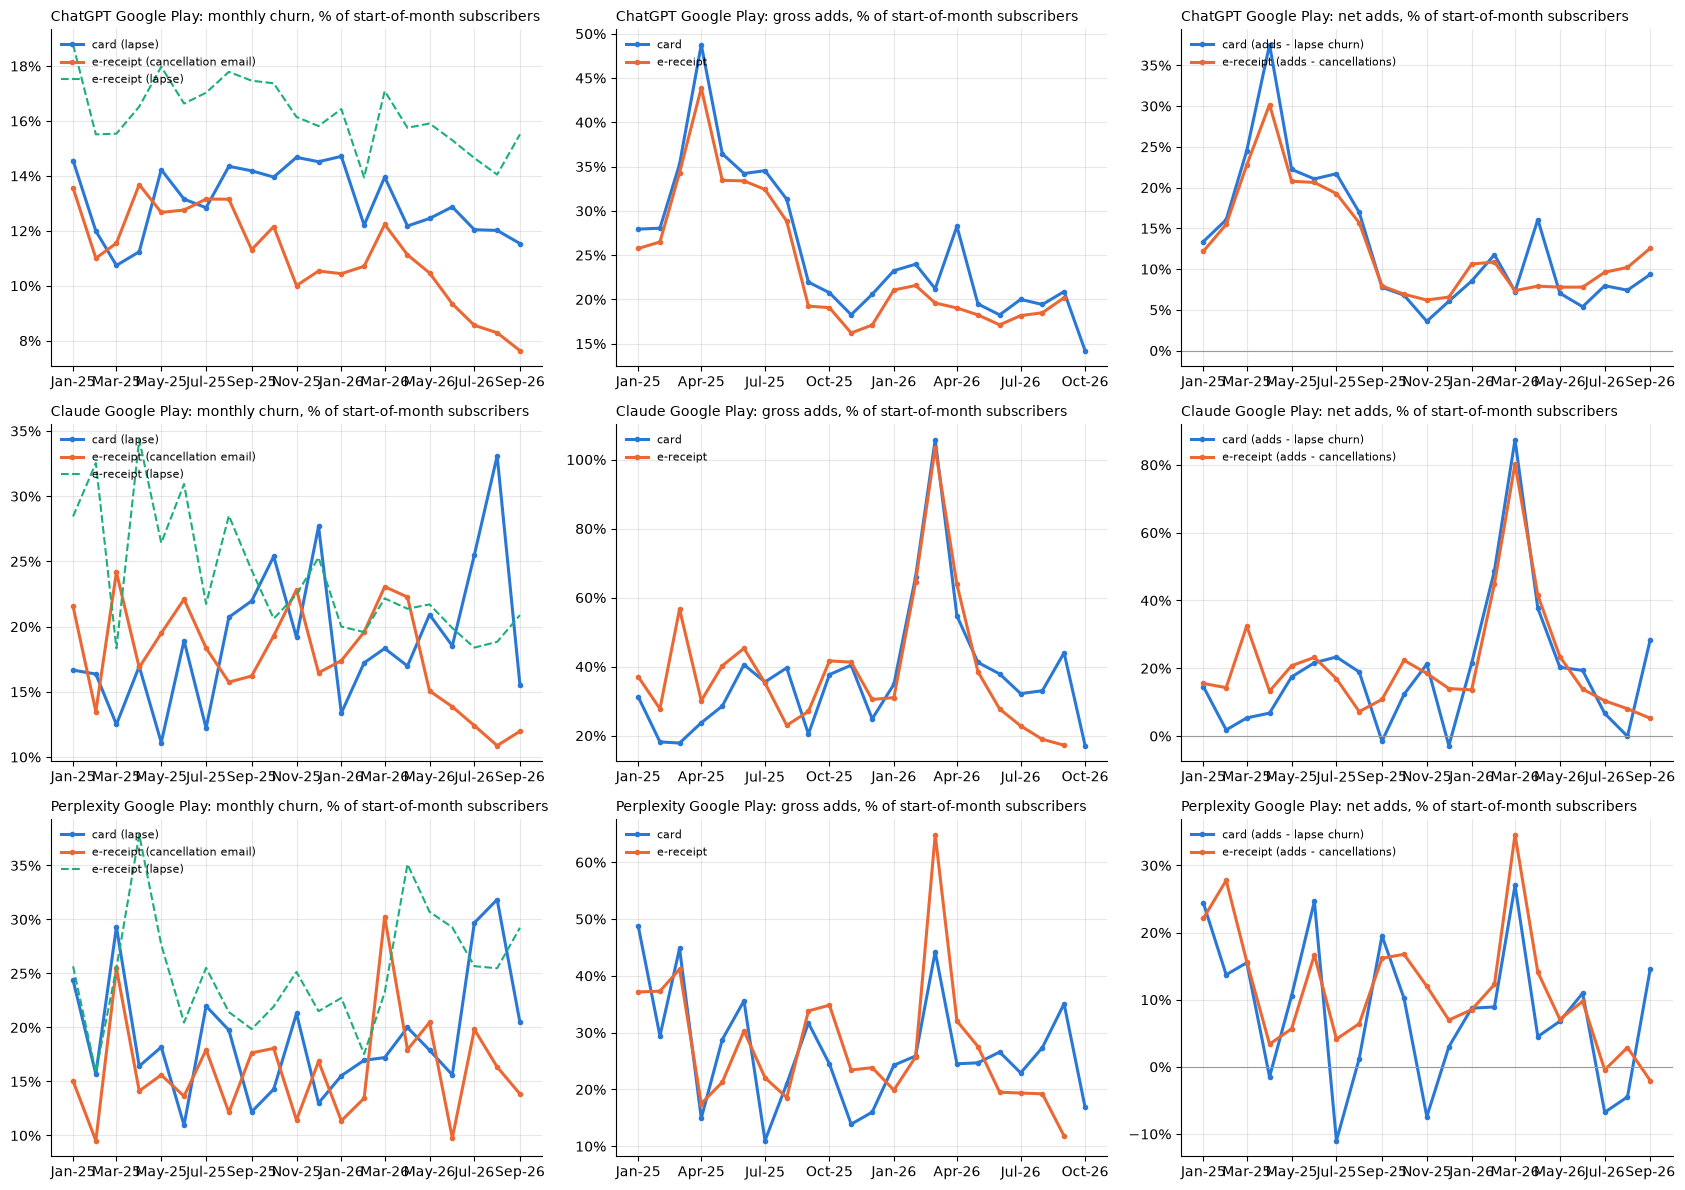

In [15]:
C3 = {"card": "#2a78d6", "cancel": "#eb6834", "rlapse": "#1baf7a"}
fig, axes = plt.subplots(len(GP), 3, figsize=(17, 4 * len(GP)))
for row, p in zip(axes, GP):
    c = card[card.provider == p].set_index("month"); r = rec[rec.provider == p].set_index("month")
    xc, xr = c.index.to_timestamp(), r.index.to_timestamp()
    ax = row[0]
    ax.plot(xc, c.churn_rate, color=C3["card"], lw=2.2, marker="o", ms=3, label="card (lapse)")
    ax.plot(xr, r.cancel_rate, color=C3["cancel"], lw=2.2, marker="o", ms=3, label="e-receipt (cancellation email)")
    ax.plot(xr, r.churn_rate, color=C3["rlapse"], lw=1.5, ls="--", label="e-receipt (lapse)")
    ax.set_title(f"{NAMES[p]} Google Play: monthly churn, % of start-of-month subscribers", fontsize=10, loc="left")
    ax = row[1]
    ax.plot(xc, c.add_rate, color=C3["card"], lw=2.2, marker="o", ms=3, label="card")
    ax.plot(xr, r.add_rate, color=C3["cancel"], lw=2.2, marker="o", ms=3, label="e-receipt")
    ax.set_title(f"{NAMES[p]} Google Play: gross adds, % of start-of-month subscribers", fontsize=10, loc="left")
    ax = row[2]
    ax.plot(xc, c.net_rate, color=C3["card"], lw=2.2, marker="o", ms=3, label="card (adds - lapse churn)")
    ax.plot(xr, r.net_rate_cancel, color=C3["cancel"], lw=2.2, marker="o", ms=3, label="e-receipt (adds - cancellations)")
    ax.axhline(0, color="#999", lw=0.8)
    ax.set_title(f"{NAMES[p]} Google Play: net adds, % of start-of-month subscribers", fontsize=10, loc="left")
    for ax in row:
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y")); ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

In [16]:
# Jul-Aug 2026: Claude and Perplexity Google Play (and Gemini) card charges skip a month for 10-21% of subscribers (section 2),
# not seen in the receipts; a 45-day cutoff reads each as churn. ChatGPT's equivalent (the truncated "GOOGLE *CHATGP"
# descriptor, Nov 2025 and Jul-Aug 2026) is fixed in the pull, so these months are clean for ChatGPT.
GAP_MONTHS = pd.PeriodIndex(["2026-07", "2026-08"], freq="M")

def stats(p, excl=None):
    j = card[card.provider == p].set_index("month")[["churn_rate", "add_rate", "net_rate", "subs_start"]].join(
        rec[rec.provider == p].set_index("month")[["cancel_rate", "churn_rate", "add_rate", "net_rate_cancel", "subs_start"]],
        rsuffix="_r", how="inner").dropna(subset=["churn_rate", "cancel_rate"])
    if excl is not None: j = j[~j.index.isin(excl)]
    ratio = j.churn_rate / j.cancel_rate
    ratio_l = j.churn_rate / j.churn_rate_r
    return pd.Series({
        "months": len(j), "card subs (median)": j.subs_start.median(), "receipt subs (median)": j.subs_start_r.median(),
        "card churn rate (mean)": j.churn_rate.mean(), "receipt cancel rate (mean)": j.cancel_rate.mean(),
        "receipt lapse rate (mean)": j.churn_rate_r.mean(),
        "corr churn: card vs cancel": j.churn_rate.corr(j.cancel_rate),
        "corr churn MoM change: card vs cancel": j.churn_rate.diff().corr(j.cancel_rate.diff()),
        "ratio card / cancel (mean)": ratio.mean(), "ratio card / cancel (CV)": ratio.std() / ratio.mean(),
        "corr churn: card vs receipt lapse": j.churn_rate.corr(j.churn_rate_r),
        "ratio card / receipt lapse (mean)": ratio_l.mean(), "ratio card / receipt lapse (CV)": ratio_l.std() / ratio_l.mean(),
        "corr gross add rate": j.add_rate.corr(j.add_rate_r), "corr net add rate": j.net_rate.corr(j.net_rate_cancel)})

ST = pd.DataFrame({**{NAMES[p]: stats(p) for p in GP}, **{f"{NAMES[p]} ex gap months": stats(p, GAP_MONTHS) for p in GP}})
pct = [i for i in ST.index if "rate (mean)" in i]
ST.style.format(lambda v: f"{v:,.2f}").format(lambda v: f"{v:.1%}", subset=pd.IndexSlice[pct, :]).format(
    lambda v: f"{v:,.0f}", subset=pd.IndexSlice[["months", "card subs (median)", "receipt subs (median)"], :])

,ChatGPT,Claude,Perplexity,ChatGPT ex gap months,Claude ex gap months,Perplexity ex gap months
months,21,21,21,19,19,19
card subs (median),"10,207",146,100,"9,557",132,98
receipt subs (median),"10,584",276,172,"10,407",235,171
card churn rate (mean),13.1%,19.0%,19.2%,13.2%,17.9%,18.0%
receipt cancel rate (mean),11.2%,17.8%,16.2%,11.4%,18.4%,16.0%
receipt lapse rate (mean),16.2%,23.7%,25.1%,16.4%,24.2%,25.1%
corr churn: card vs cancel,0.29,-0.45,0.28,0.17,-0.17,0.28
corr churn MoM change: card vs cancel,0.18,-0.30,0.41,0.21,-0.30,0.36
ratio card / cancel (mean),1.20,1.16,1.25,1.17,1.02,1.20
ratio card / cancel (CV),0.16,0.50,0.32,0.16,0.33,0.31


In [17]:
# monthly detail, for reading the charts
D = card[["provider", "month", "subs_start", "churn_rate"]].merge(
    rec[["provider", "month", "subs_start", "cancel_rate", "churn_rate"]], on=["provider", "month"], suffixes=("_card", "_rec"))
D["ratio card / cancel"] = D.churn_rate_card / D.cancel_rate
D.assign(provider=D.provider.map(NAMES)).set_index(["provider", "month"]).style.format(
    {"subs_start_card": "{:,.0f}", "subs_start_rec": "{:,.0f}", "churn_rate_card": "{:.1%}", "cancel_rate": "{:.1%}",
     "churn_rate_rec": "{:.1%}", "ratio card / cancel": "{:.2f}"}, na_rep="")

**Findings (45-day cutoff on both sides, ChatGPT descriptor fixed).**
- **Gross adds and net adds move together** for ChatGPT: correlation of monthly rates 0.97 (gross adds) and 0.95 (net adds). For Claude it is 0.78 / 0.84, and for Perplexity 0.61 / 0.68.
- **Card lapse churn tracks e-receipt lapse churn** for ChatGPT: correlation 0.63, and a stable ratio (card 0.81x receipts, CV 0.08). The card rate is about 13% a month against 16% on receipts. Both sources measure the same thing in the same way, and they agree.
- **Card churn does not track e-receipt cancellations:** correlation 0.29 on levels, 0.18 on monthly changes. The card/cancellation ratio drifts from about 1.0-1.1 in 2025 to 1.4-1.5 from Jun 2026. Card churn is steady at 12-15%, while e-receipt cancellations fall from about 13% to 7.6% (Sep 2026).
- **So the 2026 divergence is inside the e-receipts.** Cancellations as a share of e-receipt lapses fall from about 0.70-0.77 to 0.49 (section 8). A growing share of ChatGPT Google Play subscriptions end without a cancellation email.
- **Claude and Perplexity Google Play are too small to judge** (50-1,400 card subscribers a month). Their ratios have a CV of about 0.3, even outside Jul-Aug 2026.
- About 60-71% of e-receipt cancellations fall inside a seen subscription. The rest have no paid receipt in the channel (trials, or sign-ups before the receipt window).

## 6. How much earlier do cancellation emails arrive?

For e-receipt cancellations inside a spell:
- **days before the next charge:** expected next charge (last paid receipt + median cycle) minus the cancellation email date. Google Play sends the email when the user cancels, which can be any time in the paid month.
- **days before the card rule knows:** last paid receipt + 45-day cutoff + 10 days posting lag, minus the email date. This is how much earlier the e-receipts flag the churn than the card lapse rule can confirm it.

In [18]:
x = inside[inside.dt >= "2025-01-01"].copy()
x["thr_card"] = [THR[(p, "google_play")] for p in x.provider]
x["before_due"] = (x.next_due - x.dt).dt.days
x["before_card"] = (x["last"] + pd.to_timedelta(x.thr_card + N.CARD_LAG, unit="D") - x.dt).dt.days
q = x.groupby("provider")[["before_due", "before_card"]].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack()
q.index = q.index.map(NAMES)
q.style.format("{:.0f}")

**Finding: e-receipts flag churn about seven weeks before the 45-day card rule can confirm it.** The median cancellation email arrives 22-24 days before the next charge would have been due, and **46-48 days before the card rule knows** (last payment + 45 days + 10 days posting lag). A quarter of cases are 55+ days earlier. The upper deciles (80+ days) are cancellations with a later renewal receipt, e.g. cancel then resubscribe.

## 7. Nowcasting card churn from e-receipt cancellations: backtest

Card churn for a month is complete only about 24 days after it ends (45-day cutoff - 31-day cycle + 10 days lag), and the gap months are unusable. E-receipt cancellations are complete at month end. The test: at the end of month m, predict the card churn rate for m as **e-receipt cancel rate (m) x mean card/receipt ratio** over the 6 latest months whose card churn was complete at that point (m-7 to m-2). The baseline is the naive forecast: the last complete card churn rate (m-2). Scored on all months and with the card gap months excluded (neither used in the ratio nor scored).

,ChatGPT,Claude,Perplexity,ChatGPT ex gap months,Claude ex gap months,Perplexity ex gap months
months tested,17,17,17,15,15,15
MAE nowcast (pp),1.78,7.30,6.36,1.79,6.12,5.68
MAE naive (pp),1.05,4.73,6.56,1.16,3.62,5.28
mean error nowcast (pp),-1.03,-2.55,0.62,-0.94,-0.73,2.24
corr nowcast vs actual,0.18,-0.36,-0.01,-0.01,-0.09,-0.00
corr naive vs actual,0.28,0.30,-0.10,0.16,0.46,-0.23


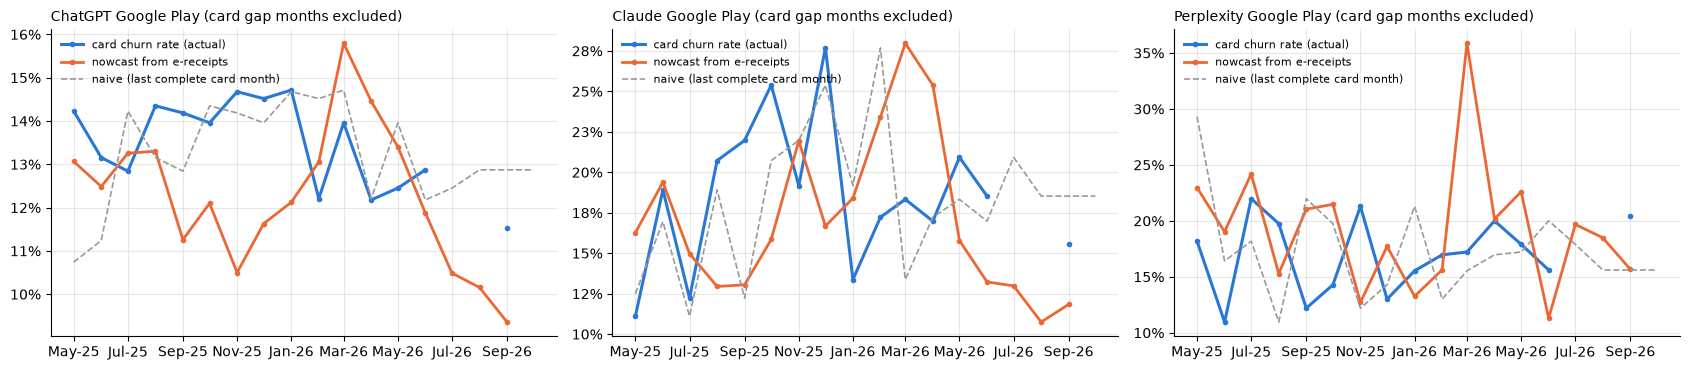

nowcasts for months whose card churn is not complete yet:


,,nowcast,ratio_used
,month,,
ChatGPT,2026-10,nan%,1.23
Claude,2026-10,nan%,0.99
Perplexity,2026-10,nan%,1.13


In [19]:
def backtest(p, win=6, gap=2, excl=None):
    j = card[card.provider == p].set_index("month")[["churn_rate"]].join(
        rec[rec.provider == p].set_index("month")[["cancel_rate"]], how="outer")
    if excl is not None: j.loc[j.index.isin(excl), "churn_rate"] = np.nan  # unusable card months: not used in ratios or scored
    out = []
    for i, m in enumerate(j.index):
        hist = j.loc[:m - gap].dropna().tail(win)
        if len(hist) < 3: continue
        ratio = (hist.churn_rate / hist.cancel_rate).mean()
        out.append({"month": m, "actual": j.churn_rate.get(m), "nowcast": j.cancel_rate.get(m) * ratio,
                    "naive": hist.churn_rate.iloc[-1], "ratio_used": ratio})
    return pd.DataFrame(out).set_index("month")

BT = {p: backtest(p) for p in GP}
BTX = {p: backtest(p, excl=GAP_MONTHS) for p in GP}
rows = {}
for name, b in [*[(NAMES[p], BT[p]) for p in GP], *[(f"{NAMES[p]} ex gap months", BTX[p]) for p in GP]]:
    e = b.dropna(subset=["actual"])
    rows[name] = {"months tested": len(e), "MAE nowcast (pp)": (e.nowcast - e.actual).abs().mean() * 100,
                      "MAE naive (pp)": (e.naive - e.actual).abs().mean() * 100,
                      "mean error nowcast (pp)": (e.nowcast - e.actual).mean() * 100,
                      "corr nowcast vs actual": e.nowcast.corr(e.actual), "corr naive vs actual": e.naive.corr(e.actual)}
display(pd.DataFrame(rows).style.format("{:.2f}").format("{:.0f}", subset=pd.IndexSlice[["months tested"], :]))

fig, axes = plt.subplots(1, len(GP), figsize=(17, 3.8))
for ax, p in zip(axes, GP):
    b = BTX[p]; x = b.index.to_timestamp()  # gap months excluded
    ax.plot(x, b.actual, color=C3["card"], lw=2.2, marker="o", ms=3, label="card churn rate (actual)")
    ax.plot(x, b.nowcast, color=C3["cancel"], lw=2, marker="o", ms=3, label="nowcast from e-receipts")
    ax.plot(x, b.naive, color="#999", lw=1.2, ls="--", label="naive (last complete card month)")
    ax.set_title(f"{NAMES[p]} Google Play (card gap months excluded)", fontsize=10, loc="left"); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y")); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
print("nowcasts for months whose card churn is not complete yet:")
pd.concat({NAMES[p]: b[b.index > DONE[(p, "google_play")]][["nowcast", "ratio_used"]] for p, b in BTX.items()}).style.format({"nowcast": "{:.1%}", "ratio_used": "{:.2f}"})

**Finding: with the ChatGPT descriptor fixed, the nowcast does not beat the naive forecast.**
- **ChatGPT:** MAE 1.8pp vs 1.05pp naive, with the nowcast running about 1pp low. Card churn is now so steady (11.5-14.7%) that "same as the last complete month" is hard to beat. The nowcast inherits the downward drift in e-receipt cancellations, and the trailing ratio lags behind it.
- The earlier result (nowcast beats naive once the gap months were excluded) came from the false card churn spikes. It does not hold on the corrected data.
- **Claude and Perplexity:** worse than or equal to naive, on small panels.

In [20]:
# exports for the app / later work
N.CACHE.mkdir(parents=True, exist_ok=True)
pd.concat([t.reset_index().assign(table=n) for n, t in {"card_family": fam, "card_provider_channel": pc, "card_plan": pl, "receipt_gp": rt}.items()]).to_parquet(N.CACHE / "cycles.parquet", index=False)
cm.to_parquet(N.CACHE / "card_monthly.parquet", index=False)
cm_plan.to_parquet(N.CACHE / "card_monthly_plan.parquet", index=False)
D.to_parquet(N.CACHE / "gp_comparison_monthly.parquet", index=False)
print("saved to", N.CACHE)

saved to C:\Users\fintan.creedon\code\exploration\ai\.cache\card_net


## Summary (45-day cutoff, ChatGPT descriptor fixed)

1. **The billing cycle is regular** (92-94% of gaps 26-35 days, median 31, members keep their cycle). p99 is about 60 days because of one-off missed charges, not because the cycle drifts. **A fixed 45-day cutoff** confirms card churn about 55 days after the last payment.
2. **Card tagging:** the truncated `GOOGLE *CHATGP` descriptor (no final T) was missed until 2026-10-26 and caused false card churn spikes for ChatGPT Google Play in Nov 2025 and Jul-Aug 2026. It is now matched. Claude, Perplexity and Gemini still show a Jul-Aug 2026 skip, probably the same kind of descriptor change; not checked yet.
3. **ChatGPT Google Play, card vs e-receipts:** gross adds and net adds trend alike (r = 0.97 / 0.95), and card lapse churn tracks e-receipt lapse churn (r = 0.63, stable ratio 0.81). **E-receipt cancellations do not track:** since March 2026 they cover a falling share of churn (cancellations / lapses 0.75 → 0.49). The nowcast built on them does not beat the naive forecast.
4. **Next step:** find out why ChatGPT Google Play subscriptions increasingly end without a cancellation email. Look at mailboxes whose Google Play renewals stop with no cancellation since March 2026: failed-payment emails, promo plans, or mailboxes that stop sending receipts. If it is involuntary churn, model it separately and add it to the cancellations.

## 8. ChatGPT Google Play: monthly churn counts, card vs e-receipt

Top: the number of churns each month from each source, on one axis (the card and receipt panels have similar numbers of ChatGPT Google Play subscribers: about 2-24k on cards, 3-14k on receipts). Card churn uses the 45-day lapse rule and is shown for complete months only; e-receipt cancellations are counted to the last full month. Bottom: the same as a share of start-of-month subscribers, with the card / cancellation ratio. Grey bands are Jul-Aug 2026, the card gap months for the other Google Play providers (ChatGPT is clean since the `CHATGP` descriptor fix).

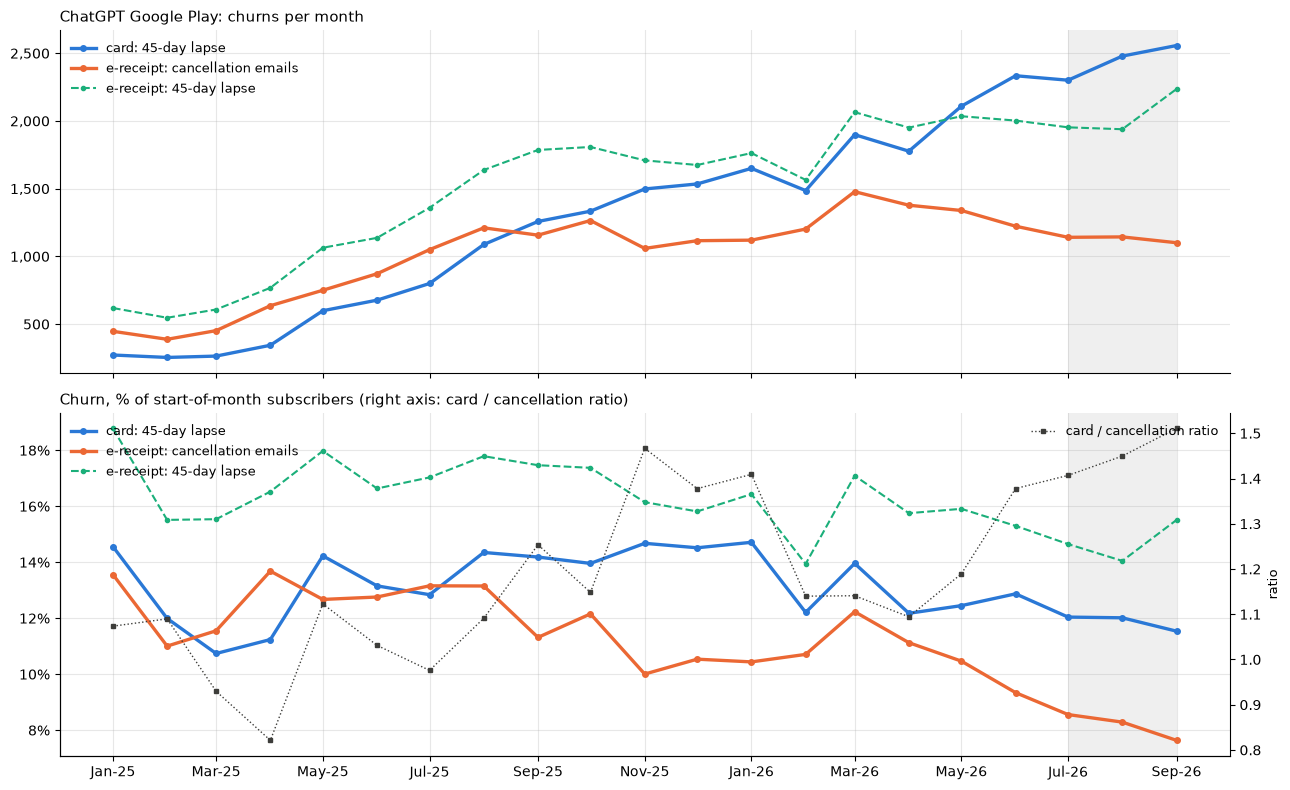

,card subs (start),card churn,receipt subs (start),receipt cancellations,receipt lapse churn,card churn rate,receipt cancel rate,card / cancel ratio,card gap month
month,,,,,,,,,
2025-01,"1,868",272,"3,296",447,619,14.6%,13.6%,1.07,False
2025-02,"2,118",254,"3,526",388,547,12.0%,11.0%,1.09,False
2025-03,"2,458",264,"3,913",452,608,10.7%,11.6%,0.93,False
2025-04,"3,061",344,"4,648",636,768,11.2%,13.7%,0.82,False
2025-05,"4,210",599,"5,919",750,"1,064",14.2%,12.7%,1.12,False
2025-06,"5,146",677,"6,835",872,"1,137",13.2%,12.8%,1.03,False
2025-07,"6,230",800,"7,980","1,050","1,359",12.8%,13.2%,0.98,False
2025-08,"7,582","1,088","9,208","1,211","1,638",14.3%,13.2%,1.09,False
2025-09,"8,868","1,258","10,225","1,157","1,786",14.2%,11.3%,1.25,False


In [21]:
c = card[card.provider == "chatgpt"].set_index("month")
r = rec[rec.provider == "chatgpt"].set_index("month")
months = c.index.union(r.index)
x = months.to_timestamp()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for m in GAP_MONTHS:
    for ax in (a1, a2):
        ax.axvspan(m.to_timestamp(), (m + 1).to_timestamp(), color="#999", alpha=0.15, lw=0)
a1.plot(x, c.churn.reindex(months), color=C3["card"], lw=2.4, marker="o", ms=4, label="card: 45-day lapse")
a1.plot(x, r.cancels.reindex(months), color=C3["cancel"], lw=2.4, marker="o", ms=4, label="e-receipt: cancellation emails")
a1.plot(x, r.churn.reindex(months), color=C3["rlapse"], lw=1.5, ls="--", marker="o", ms=3, label="e-receipt: 45-day lapse")
a1.set_title("ChatGPT Google Play: churns per month", fontsize=11, loc="left")
a1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
a2.plot(x, c.churn_rate.reindex(months), color=C3["card"], lw=2.4, marker="o", ms=4, label="card: 45-day lapse")
a2.plot(x, r.cancel_rate.reindex(months), color=C3["cancel"], lw=2.4, marker="o", ms=4, label="e-receipt: cancellation emails")
a2.plot(x, r.churn_rate.reindex(months), color=C3["rlapse"], lw=1.5, ls="--", marker="o", ms=3, label="e-receipt: 45-day lapse")
a2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a2.set_title("Churn, % of start-of-month subscribers (right axis: card / cancellation ratio)", fontsize=11, loc="left")
a3 = a2.twinx()
a3.plot(x, (c.churn_rate / r.cancel_rate).reindex(months), color="#3d3d3a", lw=1, ls=":", marker="s", ms=3, label="card / cancellation ratio")
a3.set_ylabel("ratio", fontsize=9); a3.spines[["top"]].set_visible(False)
for ax in (a1, a2):
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper left")
a3.legend(frameon=False, fontsize=9, loc="upper right")
a2.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.tight_layout(); plt.show()

T = pd.DataFrame({"card subs (start)": c.subs_start, "card churn": c.churn, "receipt subs (start)": r.subs_start,
                  "receipt cancellations": r.cancels, "receipt lapse churn": r.churn,
                  "card churn rate": c.churn_rate, "receipt cancel rate": r.cancel_rate}).reindex(months)
T["card / cancel ratio"] = T["card churn rate"] / T["receipt cancel rate"]
T["card gap month"] = T.index.isin(GAP_MONTHS)
T.style.format({**{k: "{:,.0f}" for k in ["card subs (start)", "card churn", "receipt subs (start)", "receipt cancellations", "receipt lapse churn"]},
                "card churn rate": "{:.1%}", "receipt cancel rate": "{:.1%}", "card / cancel ratio": "{:.2f}"}, na_rep="")

**Findings: where they track and where they deviate (ChatGPT descriptor fixed).**
- **Card churn rises steadily** from about 270 a month (Jan 2025) to 2,560 (Sep 2026), at a steady 11.5-14.7% of start-of-month subscribers, as the card base grows from 1.9k to 22k.
- **E-receipt lapse churn moves with it:** 620 → 2,240, at 14-19%. In 2026 the counts are close (e.g. May 2,035 vs card 2,109; Sep 2,236 vs 2,557), although the card base has grown faster (about 12x since Jan 2025 vs 4x on receipts).
- **E-receipt cancellations track until about Mar 2026, then fall away:** they rise with the others to 1,478 in March, then decline to about 1,100 a month while both lapse measures keep rising. As a share of start-of-month subscribers, cancellations fall from about 11-13% to 7.6%.
- **The deviation is inside the e-receipts.** Cancellations as a share of e-receipt lapses fall from about 0.70-0.77 (2025 to Mar 2026) to 0.58 (Jul-Aug) and 0.49 (Sep). A growing share of subscriptions end without a cancellation email. Possible causes: involuntary churn (failed payments send no cancellation email), promo or discounted subscriptions ending, or lower capture of cancellation emails.
- **Practical read:** for ChatGPT Google Play, e-receipt *lapse* churn is the close match to card churn, but it is no faster (it also needs 45 days after the last receipt). Cancellation emails are faster, but their coverage of churn has been falling since March 2026, so they need correcting before they can nowcast card churn.